# Section A — Dataset & EDA

## A1 — Dataset Loading & Audit

In [ ]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/airline_passenger_satisfaction.csv")

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display data types
print("\nData Types:")
print(df.dtypes)

# Display missing-value counts
print("\nMissing Values:")
print(df.isnull().sum())

# Display target/class distribution
print("\nTarget Distribution:")
print(df["Satisfaction"].value_counts())

Dataset Shape: (129880, 24)

Data Types:
ID                                          int64
Gender                                        str
Age                                         int64
Customer Type                                 str
Type of Travel                                str
Class                                         str
Flight Distance                             int64
Departure Delay                             int64
Arrival Delay                             float64
Departure and Arrival Time Convenience      int64
Ease of Online Booking                      int64
Check-in Service                            int64
Online Boarding                             int64
Gate Location                               int64
On-board Service                            int64
Seat Comfort                                int64
Leg Room Service                            int64
Cleanliness                                 int64
Food and Drink                              int64
In-flight

## A2 — EDA Visualisations

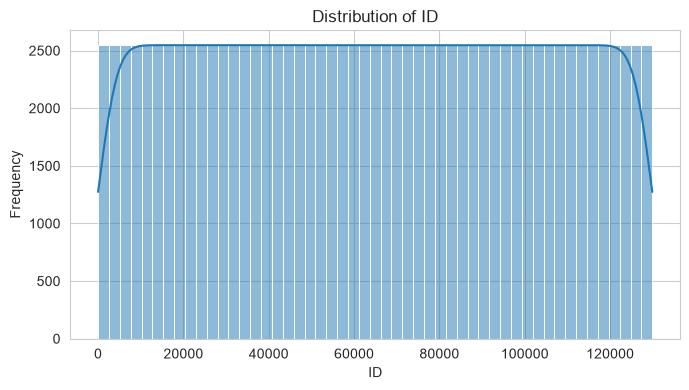

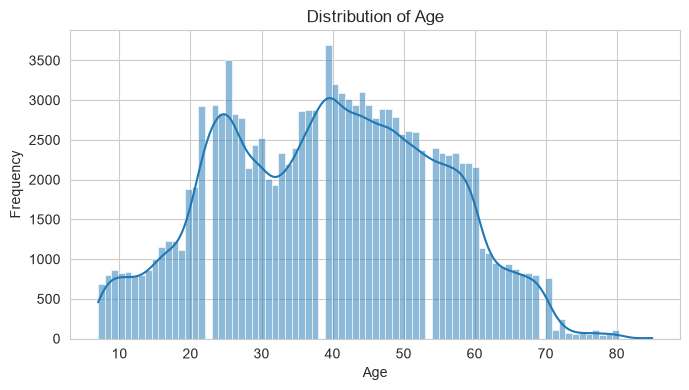

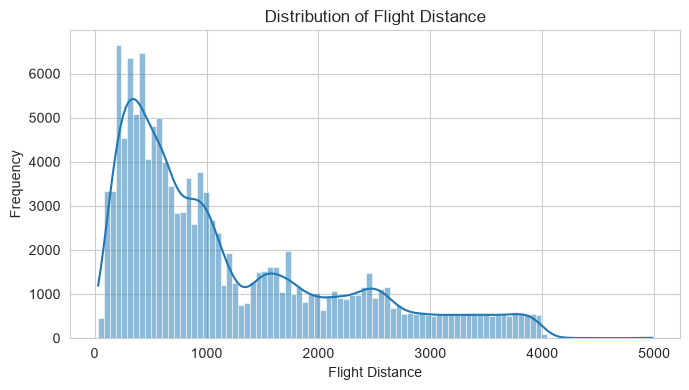

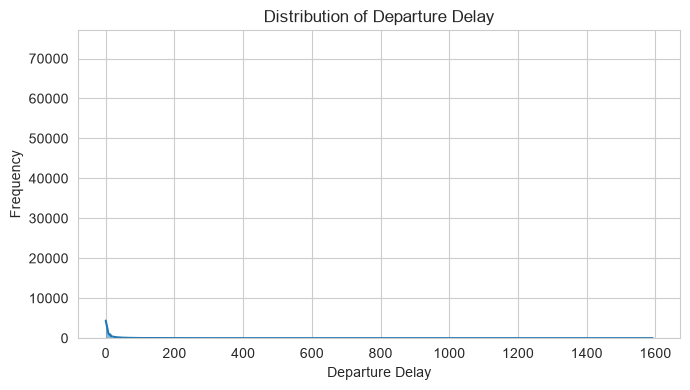

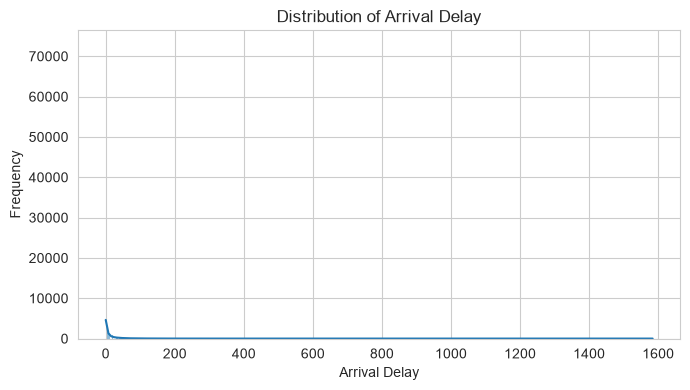

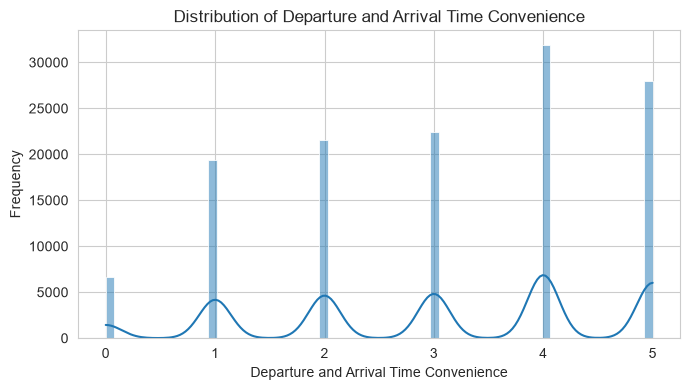

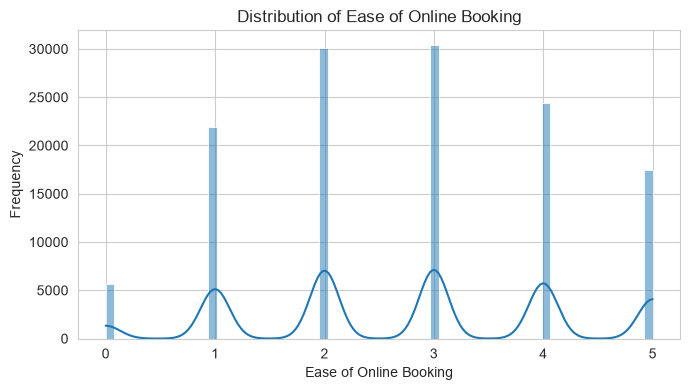

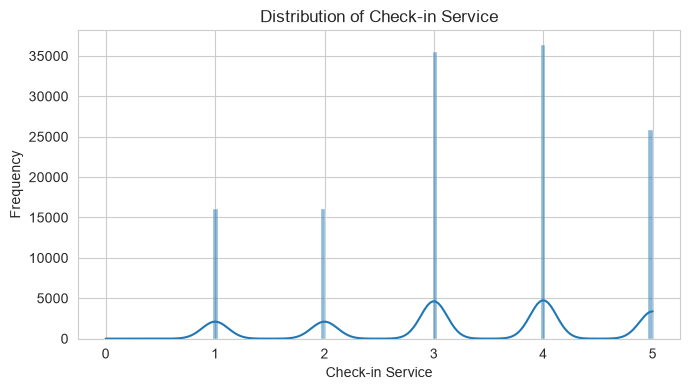

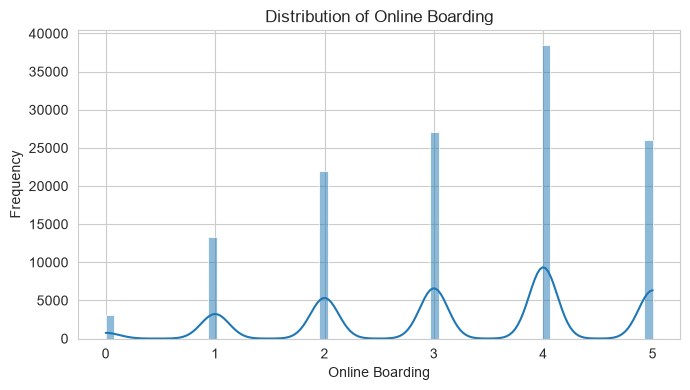

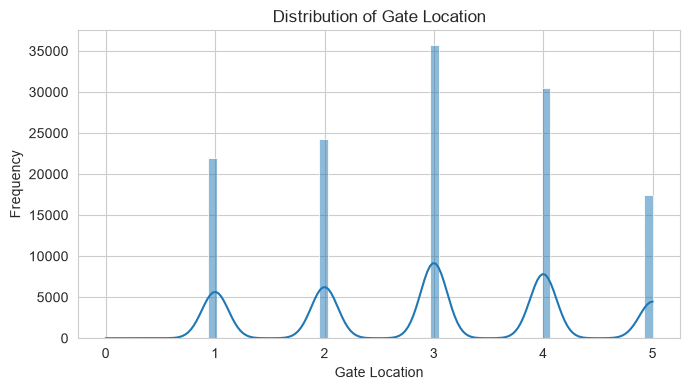

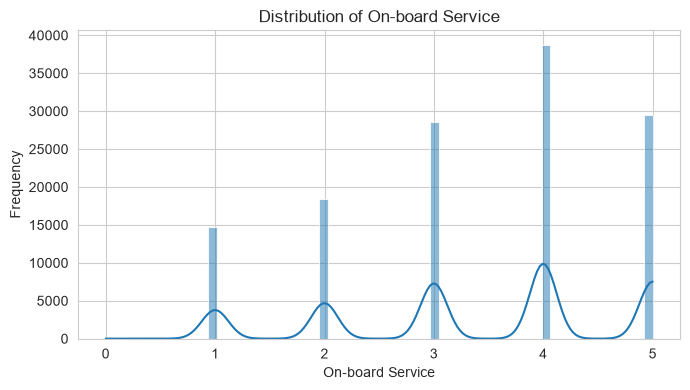

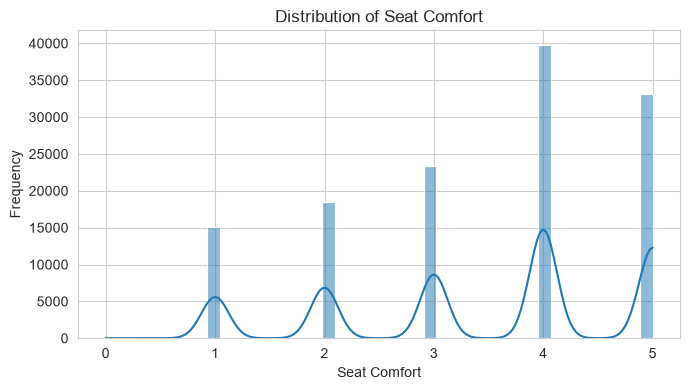

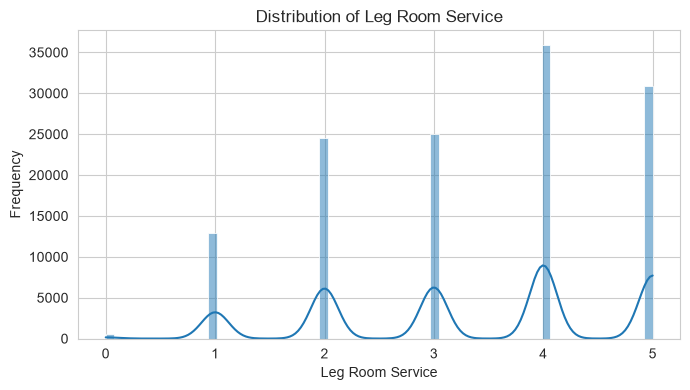

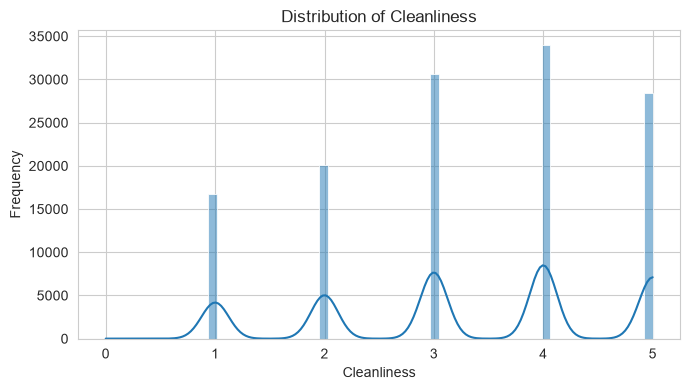

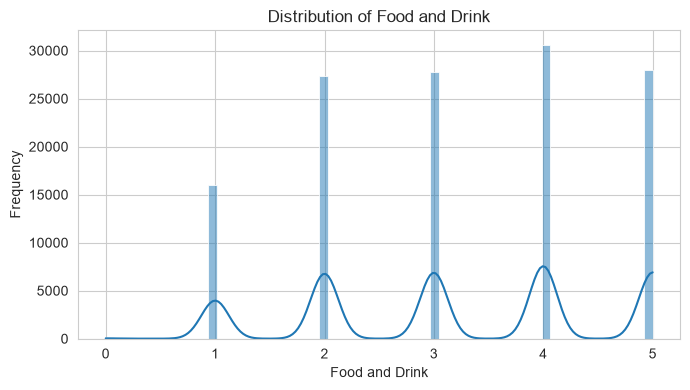

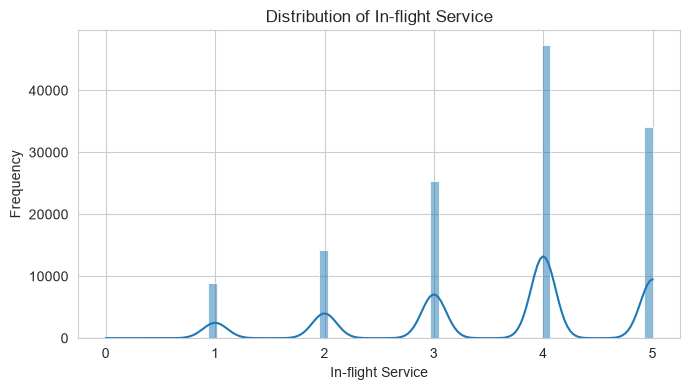

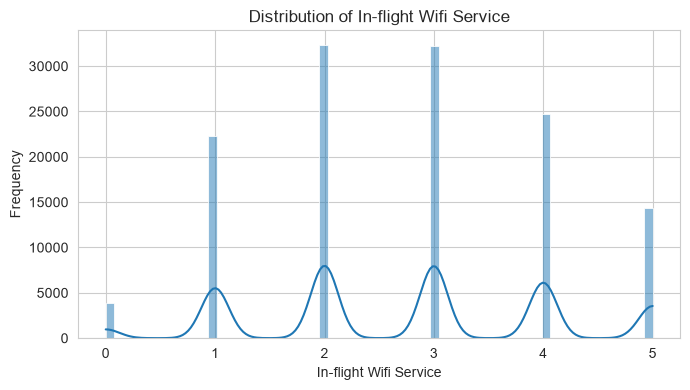

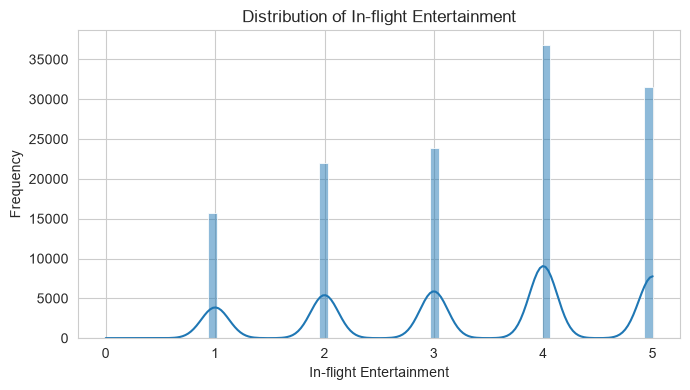

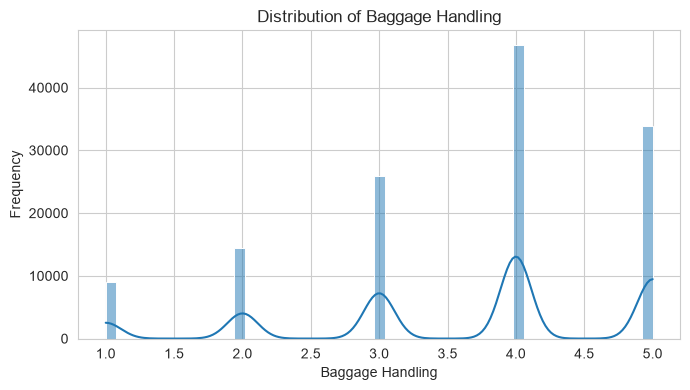

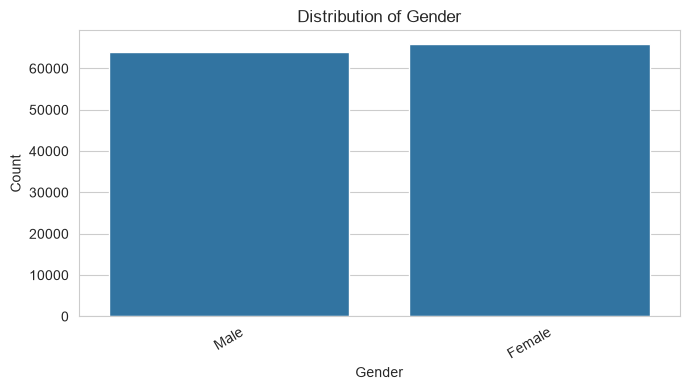

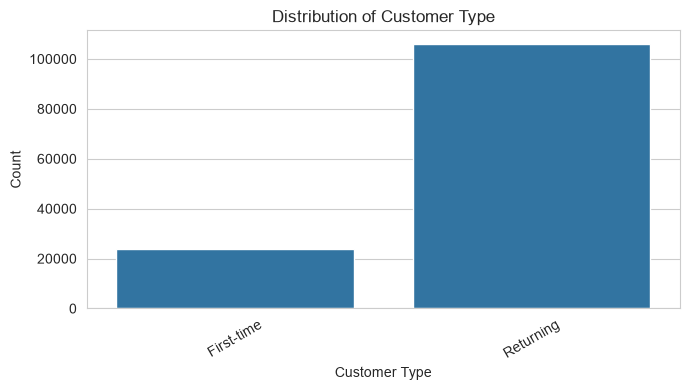

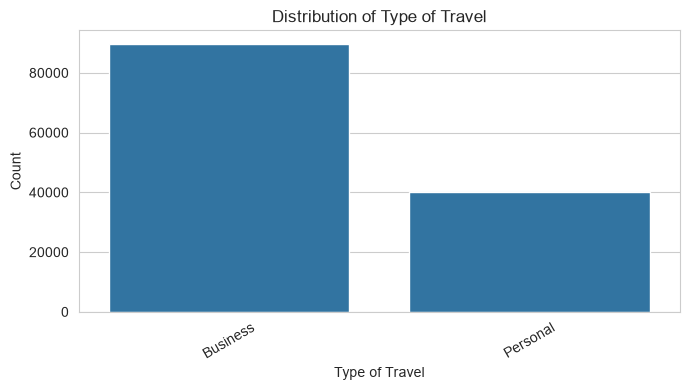

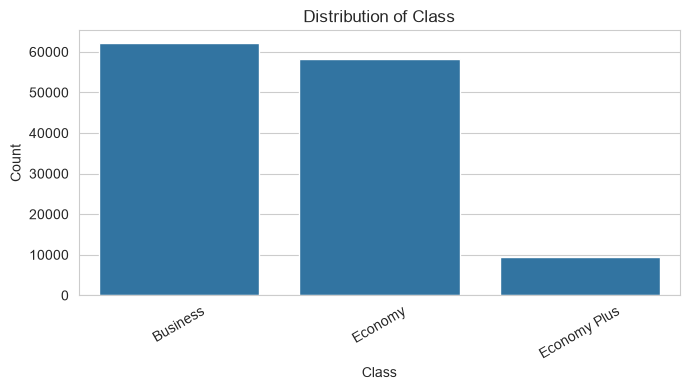

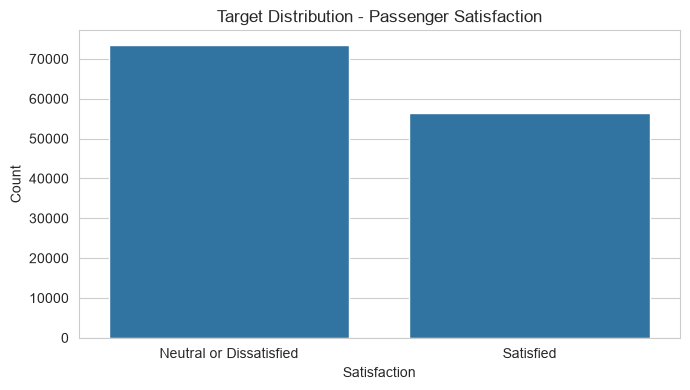

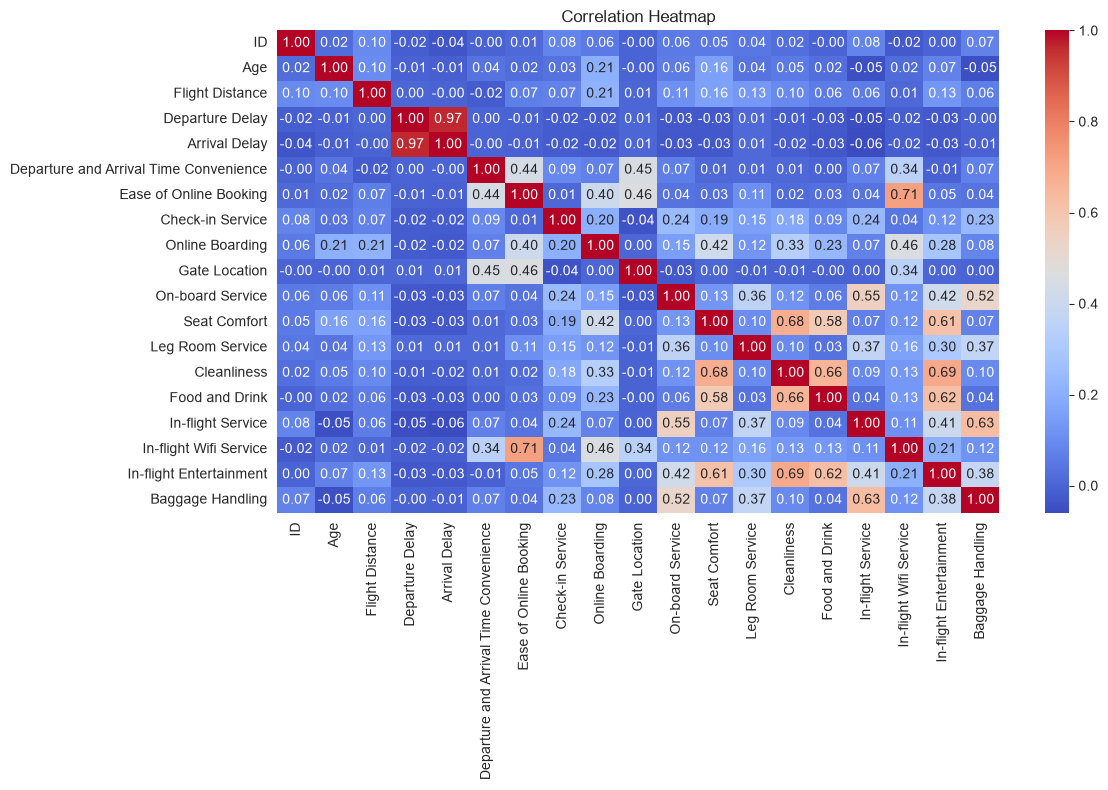

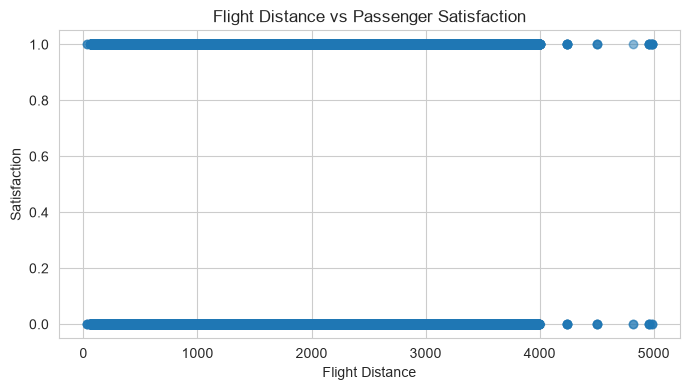

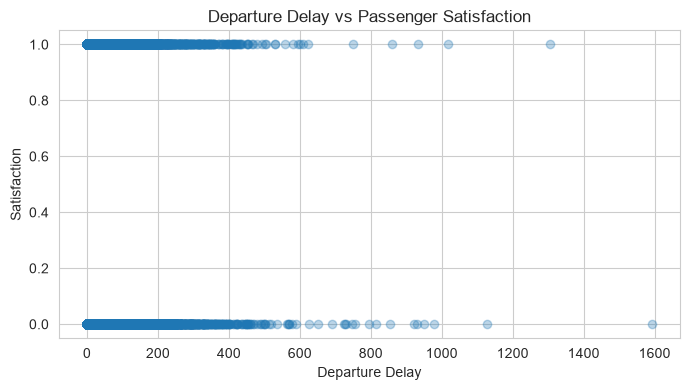

In [17]:
# Separate numerical and categorical features
numerical_features = df.select_dtypes(include=["int64", "float64"]).columns
categorical_features = df.select_dtypes(include=["object"]).columns

# --------------------------------------------------
# Distribution plots for numerical features
# --------------------------------------------------

for column in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[column], kde=True)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


# --------------------------------------------------
# Distribution plots for categorical features
# --------------------------------------------------

for column in categorical_features:
    if column != "Satisfaction":
        plt.figure(figsize=(7, 4))
        sns.countplot(data=df, x=column)
        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Count")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()


# --------------------------------------------------
# Target distribution
# --------------------------------------------------

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Satisfaction")
plt.title("Target Distribution - Passenger Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Correlation heatmap
# --------------------------------------------------

plt.figure(figsize=(12, 8))
sns.heatmap(
    df[numerical_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Scatter plot 1: Flight Distance vs Satisfaction
# --------------------------------------------------

satisfaction_numeric = df["Satisfaction"].map({
    "Neutral or Dissatisfied": 0,
    "Satisfied": 1
})

plt.figure(figsize=(7, 4))
plt.scatter(
    df["Flight Distance"],
    satisfaction_numeric,
    alpha=0.3
)
plt.title("Flight Distance vs Passenger Satisfaction")
plt.xlabel("Flight Distance")
plt.ylabel("Satisfaction")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Scatter plot 2: Departure Delay vs Satisfaction
# --------------------------------------------------

plt.figure(figsize=(7, 4))
plt.scatter(
    df["Departure Delay"],
    satisfaction_numeric,
    alpha=0.3
)
plt.title("Departure Delay vs Passenger Satisfaction")
plt.xlabel("Departure Delay")
plt.ylabel("Satisfaction")
plt.tight_layout()
plt.show()

## A3 — Insight Commentary

### Observations

- **Feature distributions:** The distribution plots show the spread and frequency of the numerical and categorical features in the dataset.

- **Target distribution:** The target distribution shows the number of passengers belonging to the Satisfied and Neutral or Dissatisfied classes.

- **Correlation heatmap:** The heatmap shows the relationships between the numerical features and helps identify features with relatively stronger correlations.

- **Flight Distance vs Satisfaction:** The scatter plot shows how the two satisfaction classes are distributed across different flight distances.

- **Departure Delay vs Satisfaction:** The scatter plot shows how passenger satisfaction is distributed across different departure delay values.

# Section B — Preprocessing & Feature Engineering

## B1 — Data Cleaning

In [20]:
# ============================================================
# B1 — DATA CLEANING
# ============================================================

# Make a copy of the dataset before preprocessing
data = df.copy()

# ------------------------------------------------------------
# Remove duplicate rows
# ------------------------------------------------------------

print("Duplicate rows before removal:", data.duplicated().sum())

data = data.drop_duplicates()

print("Duplicate rows after removal:", data.duplicated().sum())


# ------------------------------------------------------------
# Remove ID column
# ------------------------------------------------------------

# ID is only an identifier and does not provide useful
# predictive information for passenger satisfaction

data = data.drop(columns=["ID"])


# ------------------------------------------------------------
# Handle missing values
# ------------------------------------------------------------

print("\nMissing values before treatment:")
print(data.isnull().sum()[data.isnull().sum() > 0])

# Fill missing Arrival Delay values with the median
# Median is less affected by extreme delay values

data["Arrival Delay"] = data["Arrival Delay"].fillna(
    data["Arrival Delay"].median()
)

print("\nMissing values after treatment:")
print(data.isnull().sum()[data.isnull().sum() > 0])


# ------------------------------------------------------------
# Check numerical outliers
# ------------------------------------------------------------

numerical_columns = data.select_dtypes(
    include=["int64", "float64"]
).columns

print("\nOutlier counts using the IQR method:")

for column in numerical_columns:

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ).sum()

    print(f"{column}: {outliers}")

Duplicate rows before removal: 0
Duplicate rows after removal: 0

Missing values before treatment:
Arrival Delay    393
dtype: int64

Missing values after treatment:
Series([], dtype: int64)

Outlier counts using the IQR method:
Age: 0
Flight Distance: 2855
Departure Delay: 18098
Arrival Delay: 17492
Departure and Arrival Time Convenience: 0
Ease of Online Booking: 0
Check-in Service: 16109
Online Boarding: 0
Gate Location: 0
On-board Service: 0
Seat Comfort: 0
Leg Room Service: 0
Cleanliness: 0
Food and Drink: 0
In-flight Service: 0
In-flight Wifi Service: 0
In-flight Entertainment: 0
Baggage Handling: 0


## B2 — Encoding, Scaling & Splitting

In [21]:
# ============================================================
# B2 — ENCODING, SCALING & SPLITTING
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer


# ------------------------------------------------------------
# Separate features and target
# ------------------------------------------------------------

X = data.drop(columns=["Satisfaction"])

y = data["Satisfaction"].map({
    "Neutral or Dissatisfied": 0,
    "Satisfied": 1
})


# ------------------------------------------------------------
# Train-test split
# ------------------------------------------------------------

# 80% training and 20% testing
# Stratification maintains the same class distribution
# in both training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


# ------------------------------------------------------------
# Identify numerical and categorical features
# ------------------------------------------------------------

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)


# ------------------------------------------------------------
# Handle outliers using training-set information
# ------------------------------------------------------------

# Calculate IQR bounds only from the training data
# to avoid data leakage

outlier_bounds = {}

for column in numerical_features:

    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_bounds[column] = (
        lower_bound,
        upper_bound
    )


# Cap extreme values in both train and test sets
# using bounds calculated only from the training set

for column, (lower, upper) in outlier_bounds.items():

    X_train[column] = X_train[column].clip(
        lower=lower,
        upper=upper
    )

    X_test[column] = X_test[column].clip(
        lower=lower,
        upper=upper
    )


# ------------------------------------------------------------
# Create preprocessing pipeline
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("\nPreprocessing setup completed.")

Training set: (103904, 22)
Testing set: (25976, 22)

Numerical features:
['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling']

Categorical features:
['Gender', 'Customer Type', 'Type of Travel', 'Class']

Preprocessing setup completed.


## B3 — Feature Engineering

In [22]:
# ============================================================
# B3 — FEATURE ENGINEERING
# ============================================================

# Create a new feature representing the total delay
# experienced by the passenger

X_train["Total Delay"] = (
    X_train["Departure Delay"] +
    X_train["Arrival Delay"]
)

X_test["Total Delay"] = (
    X_test["Departure Delay"] +
    X_test["Arrival Delay"]
)

# Add the new feature to the numerical feature list
numerical_features.append("Total Delay")

print("New engineered feature: Total Delay")

print("\nUpdated numerical features:")
print(numerical_features)

New engineered feature: Total Delay

Updated numerical features:
['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling', 'Total Delay']


### Feature Engineering Justification

The `Total Delay` feature is created by combining Departure Delay and Arrival Delay. It represents the overall delay experienced by a passenger and may provide additional information about passenger satisfaction compared with considering the two delay variables separately.

# Section D — Classification Track, Part A

## D1 — Classification Model Implementation

In [23]:
# ============================================================
# D1 — CLASSIFICATION MODEL IMPLEMENTATION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

In [24]:
# ------------------------------------------------------------
# 1. Logistic Regression
# ------------------------------------------------------------

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Generate predictions
y_pred_lr = logistic_model.predict(X_test)

print("Logistic Regression predictions generated successfully.")

Logistic Regression predictions generated successfully.


In [25]:
# ------------------------------------------------------------
# 2. K-Nearest Neighbors
# ------------------------------------------------------------

knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5
    ))
])

# Train the model
knn_model.fit(X_train, y_train)

# Generate predictions
y_pred_knn = knn_model.predict(X_test)

print("KNN predictions generated successfully.")

KNN predictions generated successfully.


In [26]:
# ------------------------------------------------------------
# 3. Gaussian Naive Bayes
# ------------------------------------------------------------

nb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GaussianNB())
])

# Train the model
nb_model.fit(X_train, y_train)

# Generate predictions
y_pred_nb = nb_model.predict(X_test)

print("Gaussian Naive Bayes predictions generated successfully.")

Gaussian Naive Bayes predictions generated successfully.


In [27]:
# ------------------------------------------------------------
# 4. Decision Tree Classifier
# ------------------------------------------------------------

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ))
])

# Train the model
dt_model.fit(X_train, y_train)

# Generate predictions
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree predictions generated successfully.")

Decision Tree predictions generated successfully.


In [28]:
# ------------------------------------------------------------
# 5. Support Vector Classifier
# ------------------------------------------------------------

svc_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        C=1.0,
        kernel="linear",
        random_state=42
    ))
])

# Train the model
svc_model.fit(X_train, y_train)

# Generate predictions
y_pred_svc = svc_model.predict(X_test)

print("SVC predictions generated successfully.")

SVC predictions generated successfully.


## D2 — Model Evaluation

In [29]:
# ============================================================
# D2 — MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix
)

# Store predictions from all five models
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "KNN": y_pred_knn,
    "Gaussian Naive Bayes": y_pred_nb,
    "Decision Tree": y_pred_dt,
    "SVC": y_pred_svc
}


# ------------------------------------------------------------
# Calculate Accuracy and Weighted F1 Score
# ------------------------------------------------------------

results = []

for model_name, predictions in model_predictions.items():

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    weighted_f1 = f1_score(
        y_test,
        predictions,
        average="weighted"
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Weighted F1": weighted_f1
    })


# Create comparison table
comparison_table = pd.DataFrame(results)

comparison_table

# ------------------------------------------------------------
# Final preliminary comparison table
# ------------------------------------------------------------

comparison_table = comparison_table.sort_values(
    by="Weighted F1",
    ascending=False
).reset_index(drop=True)

comparison_table

,Model,Accuracy,Weighted F1
0,Decision Tree,0.946258,0.946125
1,KNN,0.930012,0.929711
2,SVC,0.878734,0.878319
3,Logistic Regression,0.877618,0.877340
4,Gaussian Naive Bayes,0.853403,0.853262


### Preliminary Observation

The five Part-A classification algorithms were trained using the same training and testing data. Accuracy and weighted F1-score are used to compare their classification performance, while confusion matrices show the correct and incorrect predictions for each model. The comparison table provides an initial comparison of the five algorithms.